In [1]:
# Step 1: Import Pandas
import pandas as pd

# Step 2: Load Wine Quality dataset
df = pd.read_csv("dataset/WineQT.csv")

# Step 3: Display first 5 records
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1143, 13)

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null

In [3]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Duplicate Records:
0

Data Types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object


In [4]:
# Remove duplicate records
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1143, 13)


In [5]:
# Remove unnecessary ID column
df = df.drop('Id', axis=1)

print("Columns after removing ID:")
print(df.columns.tolist())

Columns after removing ID:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [6]:
# Convert quality scores into binary classes
df['good_quality'] = (df['quality'] >= 7).astype(int)

# Display target distribution
print(df['good_quality'].value_counts())

# Display category names
print("\n0 = Bad Quality")
print("1 = Good Quality")

good_quality
0    984
1    159
Name: count, dtype: int64

0 = Bad Quality
1 = Good Quality


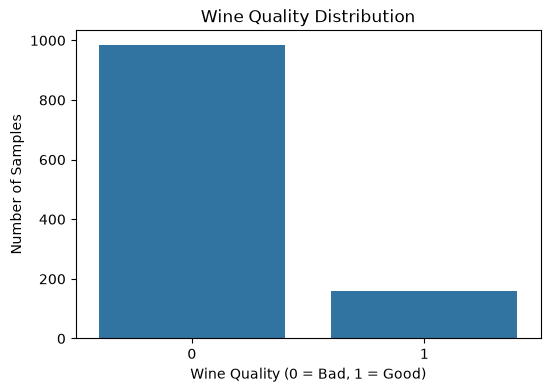

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='good_quality')

plt.title('Wine Quality Distribution')
plt.xlabel('Wine Quality (0 = Bad, 1 = Good)')
plt.ylabel('Number of Samples')

plt.show()

In [8]:
# Separate input features and target variable

X = df.drop(['quality', 'good_quality'], axis=1)

y = df['good_quality']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1143, 11)
Target Shape: (1143,)


In [10]:
# Separate input features and target variable

X = df.drop(['quality', 'good_quality'], axis=1)

y = df['good_quality']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1143, 11)
Target Shape: (1143,)


In [11]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (914, 11)
Testing data: (229, 11)


In [12]:
from sklearn.preprocessing import StandardScaler

# Create scaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [13]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [14]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 86.46 %


In [15]:
print("Classification Report:")
print(classification_report(y_test, lr_predictions))

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92       197
           1       0.52      0.34      0.42        32

    accuracy                           0.86       229
   macro avg       0.71      0.65      0.67       229
weighted avg       0.85      0.86      0.85       229



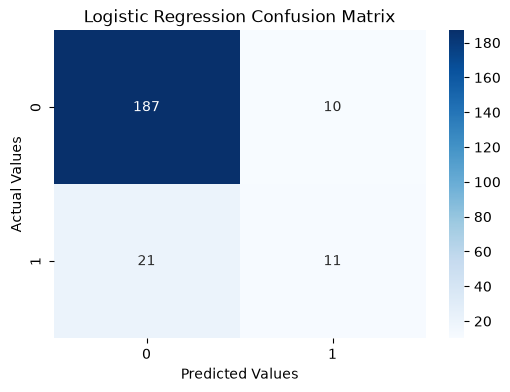

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [17]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [18]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 92.14 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       197
           1       0.79      0.59      0.68        32

    accuracy                           0.92       229
   macro avg       0.86      0.78      0.82       229
weighted avg       0.92      0.92      0.92       229



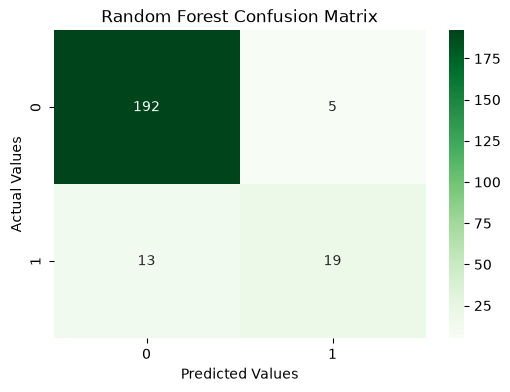

In [19]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [20]:
# Create model comparison table

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        lr_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(results)

                 Model   Accuracy
0  Logistic Regression  86.462882
1        Random Forest  92.139738


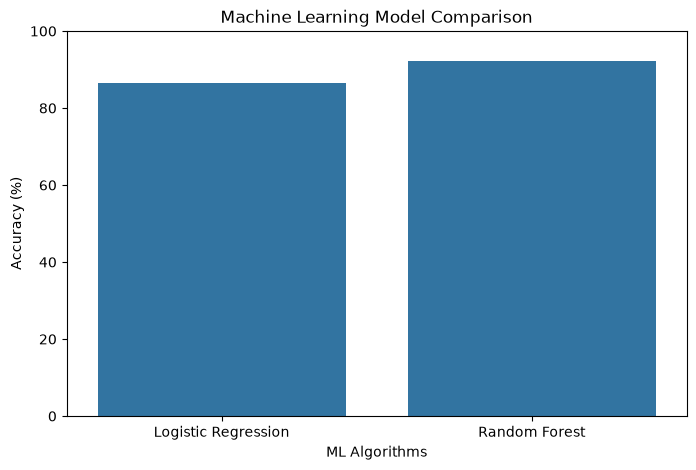

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("ML Algorithms")

plt.ylim(0, 100)

plt.show()

In [22]:
if rf_accuracy > lr_accuracy:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Best Performing Model:", best_model_name)

Best Performing Model: Random Forest


In [23]:
# Create a new wine sample

new_wine = pd.DataFrame({
    'fixed acidity': [7.4],
    'volatile acidity': [0.70],
    'citric acid': [0.00],
    'residual sugar': [1.9],
    'chlorides': [0.076],
    'free sulfur dioxide': [11.0],
    'total sulfur dioxide': [34.0],
    'density': [0.9978],
    'pH': [3.51],
    'sulphates': [0.56],
    'alcohol': [9.4]
})

print(new_wine)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4               0.7          0.0             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  
0      9.4  


In [24]:
# Prepare input based on the selected model

if best_model_name == "Logistic Regression":
    new_wine_input = scaler.transform(new_wine)
else:
    new_wine_input = new_wine

# Predict wine quality
prediction = best_model.predict(new_wine_input)

if prediction[0] == 1:
    print("Prediction: Good Quality Wine")
else:
    print("Prediction: Bad Quality Wine")

Prediction: Bad Quality Wine


In [25]:
import joblib

# Save model and preprocessing information
model_data = {
    'model': best_model,
    'scaler': scaler if best_model_name == "Logistic Regression" else None,
    'model_name': best_model_name,
    'feature_columns': X.columns.tolist()
}

# Save model
joblib.dump(model_data, "wine_quality_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [26]:
# Load saved model
loaded_data = joblib.load("wine_quality_model.pkl")

loaded_model = loaded_data['model']

# Predict using loaded model
loaded_prediction = loaded_model.predict(new_wine_input)

print("Loaded Model:", loaded_data['model_name'])

print("Predicted Wine Quality:",
      "Good" if loaded_prediction[0] == 1 else "Bad")

Loaded Model: Random Forest
Predicted Wine Quality: Bad


In [27]:
print("MODEL PERFORMANCE")
print("-------------------------")

print("Logistic Regression:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest:",
      round(rf_accuracy * 100, 2), "%")

print("\nSelected Model:", best_model_name)

MODEL PERFORMANCE
-------------------------
Logistic Regression: 86.46 %
Random Forest: 92.14 %

Selected Model: Random Forest
